# 3. From scores to action: early warning

Notebook 2 gave a score for each order. A score is not yet useful. This notebook makes it **trustworthy**
(calibration), **simple** (three risk tiers), **actionable** (decision rules) and **explained** (SHAP), and then exports
everything the Streamlit app needs.

Run after notebook 2.

In [1]:
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
import core
from core import FEATURES, MODE, TARGET

models = joblib.load(core.MODELS_FILE)
late, eta, hw = models["late"], models["eta"], models["halfwidths"]
data = core.shipped_only(core.load_dataco())
train, val, test = core.time_split(data)             # the same split as notebook 2
print(len(train), len(val), len(test))

120935 25915 25915


## 1. Calibration: make a score mean what it says

A model's raw score is not a probability. We fit an **isotonic regression on the validation split** so that a score of
0.8 means about 80% of such orders really are late. (Fitting it on validation, not test, keeps the test honest.)

In [2]:
cal = core.fit_calibrator(late.predict_proba(val[FEATURES])[:, 1], val[TARGET])
test = test.assign(p_late=cal.predict(late.predict_proba(test[FEATURES])[:, 1]))
bins = pd.cut(test["p_late"], [0, .2, .4, .6, .8, 1.0], include_lowest=True)
print("Is the calibrated probability honest? predicted vs observed late rate on the test split:")
test.groupby(bins, observed=True).agg(orders=(TARGET, "size"), predicted=("p_late", "mean"), observed=(TARGET, "mean")).round(3)

Is the calibrated probability honest? predicted vs observed late rate on the test split:


d:\annaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\annaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "d:\annaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\annaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "d:\annaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^

,orders,predicted,observed
p_late,,,
"(-0.001, 0.2]",637,0.000,0.002
"(0.2, 0.4]",9591,0.392,0.393
"(0.4, 0.6]",5829,0.415,0.397
"(0.6, 0.8]",4149,0.779,0.803
"(0.8, 1.0]",5709,0.968,0.966


In [3]:
print("Distinct calibrated scores (rounded) and how many orders have each:")
test["p_late"].round(2).value_counts().sort_index().head(15)

Distinct calibrated scores (rounded) and how many orders have each:


p_late
0.00     636
0.09       1
0.24       1
0.33      22
0.38    1185
0.39    3089
0.40    5294
0.41    3193
0.42    2624
0.48       1
0.54       1
0.56      10
0.69      27
0.75     581
0.76     685
Name: count, dtype: int64

The scores form a few **clusters**, one per shipping option (about 0.00, 0.38 to 0.40, 0.80 and 1.00). That is
the lookup table showing through again. It is also why we chose tier thresholds *after looking at these clusters*:
**High = P(late) at least 0.70**, **Low = below 0.20**, Medium in between. (A first guess of 0.75 / 0.45 did not match
the clusters and was changed.)

## 2. Risk tiers

In [4]:
test["tier"] = core.tier_of(test["p_late"])
order = ["High", "Medium", "Low"]
t = test.groupby("tier")[TARGET].agg(orders="size", late_rate="mean", late_orders="sum").reindex(order)
t["share_of_orders"] = t["orders"] / len(test); t["share_of_late_orders"] = t["late_orders"] / test[TARGET].sum()
print(f"High >= {core.TIER_HIGH}, Low < {core.TIER_LOW}; base late rate on test = {test[TARGET].mean():.3f}")
display(t.round(3))
print("Tier by shipping mode (rows are orders):")
pd.crosstab(test[MODE], test["tier"])[order]

High >= 0.7, Low < 0.2; base late rate on test = 0.576


,orders,late_rate,late_orders,share_of_orders,share_of_late_orders
tier,,,,,
High,9831,0.898,8824,0.379,0.591
Medium,15447,0.395,6105,0.596,0.409
Low,637,0.002,1,0.025,0.000


Tier by shipping mode (rows are orders):


tier,High,Medium,Low
Shipping Mode,,,
First Class,3904,0,0
Same Day,810,0,635
Second Class,5117,30,0
Standard Class,0,15417,2


## 3. Why a rule is hard to beat: the lookup table vs the model

Same test split, same metrics: does the calibrated model add anything over the 5-row table?

In [5]:
lookup = train.assign(key=core.rule_key(train)).groupby("key")[TARGET].mean()
p_rule = pd.Series(core.rule_key(test)).map(lookup).to_numpy()
p_mode = test[MODE].map(train.groupby(MODE)[TARGET].mean()).to_numpy()
pd.DataFrame({"mode only": core.score_row(test[TARGET], p_mode), "5-row lookup table": core.score_row(test[TARGET], p_rule),
              "LightGBM (calibrated)": core.score_row(test[TARGET], test["p_late"])}).T

,roc_auc,pr_auc,precision@80%recall,lift@top20%
mode only,0.746,0.84,0.653,1.65
5-row lookup table,0.777,0.86,0.677,1.70
LightGBM (calibrated),0.778,0.86,0.679,1.70


## 4. Explanation: SHAP

TreeSHAP values come straight from LightGBM (`pred_contrib=True`): for each order, how much each feature pushed the late score up
or down. Computed on 3,000 test orders. Expected: shipping mode and promised days dominate, and order hour matters only for Same Day
(a step at 12:00).

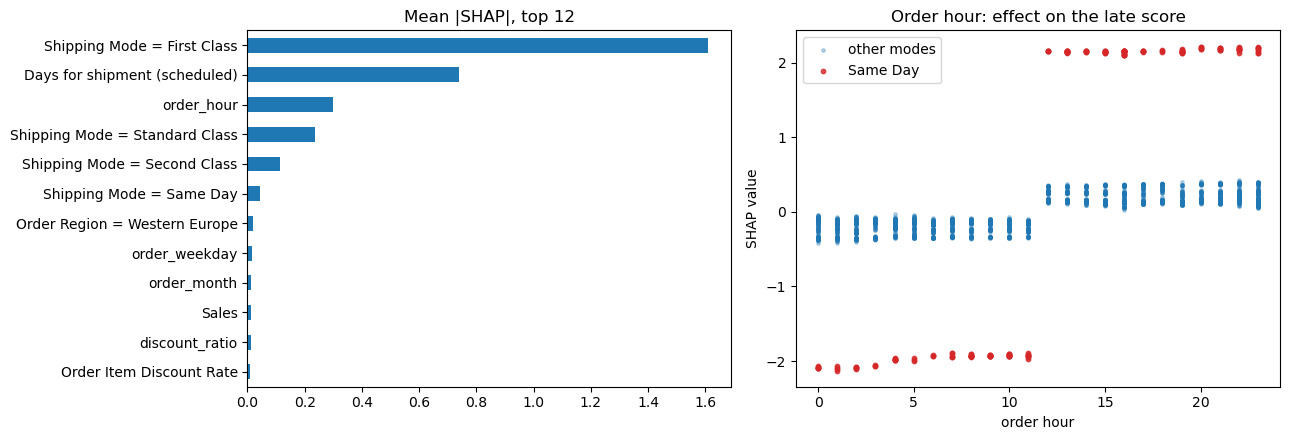

Shipping Mode = First Class       0.499
Days for shipment (scheduled)     0.230
order_hour                        0.093
Shipping Mode = Standard Class    0.074
Shipping Mode = Second Class      0.035
Shipping Mode = Same Day          0.013
Order Region = Western Europe     0.006
order_weekday                     0.004
order_month                       0.004
Sales                             0.004
dtype: float64

In [6]:
sample = test.sample(min(3000, len(test)), random_state=core.SEED)
sv, names, X = core.shap_values(late, sample)
imp = pd.Series(np.abs(sv).mean(axis=0), index=names).groupby(level=0).sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
imp.head(12)[::-1].plot.barh(ax=ax[0], title="Mean |SHAP|, top 12")
i = int(np.where(names == "order_hour")[0][0]); sd = (sample[MODE] == "Same Day").to_numpy()
ax[1].scatter(X[~sd, i], sv[~sd, i], s=6, alpha=.3, label="other modes"); ax[1].scatter(X[sd, i], sv[sd, i], s=10, alpha=.8, color="C3", label="Same Day")
ax[1].set(xlabel="order hour", ylabel="SHAP value", title="Order hour: effect on the late score"); ax[1].legend()
plt.tight_layout(); plt.show()
(imp / imp.sum()).head(10).round(3)

## 5. Decision rules

Rules turn a probability into an action. Nothing is faster than First Class, so "expedite" is not a real option. The useful
actions are to **correct the promise** and to **tell the customer**:

| Rule | When |
|---|---|
| RE-PROMISE | High tier and order value at least 200 |
| ALERT | High tier |
| WARN CUSTOMER | the 80% delivery window is 3 days or wider |
| NO ACTION | otherwise |

Judge the rules on the test split: how many late orders do they catch, and what do false alarms cost?

In [7]:
test["window"] = [2 * hw.get(m, hw["__all__"]) for m in test[MODE]]            # width of the 80% delivery window
acts = [core.recommend(p, v, w) for p, v, w in zip(test["p_late"], test["Sales"], test["window"])]
test["primary"] = [a[0].split(":")[0] for a in acts]
test["tier_flag"] = [any(x.startswith(("RE-PROMISE", "ALERT")) for x in a) for a in acts]
test["warn_flag"] = [any(x.startswith("WARN") for x in a) for a in acts]
g = test.groupby("primary")[TARGET].agg(orders="size", late_rate="mean", late_orders="sum")
g["share_of_orders"] = g["orders"] / len(test); g["share_of_late_orders"] = g["late_orders"] / test[TARGET].sum()
display(g.round(3))

def coverage(mask, name):
    tp = int((mask & (test[TARGET] == 1)).sum()); fp = int((mask & (test[TARGET] == 0)).sum())
    return {"rule": name, "share_of_orders": round(mask.mean(), 3), "precision": round(tp / max(mask.sum(), 1), 3),
            "recall": round(tp / test[TARGET].sum(), 3), "false_alarms_per_late_order_caught": round(fp / max(tp, 1), 3)}
pd.DataFrame([coverage(test["tier_flag"].to_numpy(), "High-tier alert / re-promise"),
              coverage(test["warn_flag"].to_numpy(), "Warn customer (wide window)"),
              coverage((test["tier_flag"] | test["warn_flag"]).to_numpy(), "Any action")]).set_index("rule")

,orders,late_rate,late_orders,share_of_orders,share_of_late_orders
primary,,,,,
ALERT,5323,0.895,4764,0.205,0.319
NO ACTION,635,0.000,0,0.025,0.000
RE-PROMISE,4508,0.901,4060,0.174,0.272
WARN CUSTOMER,15449,0.395,6106,0.596,0.409


,share_of_orders,precision,recall,false_alarms_per_late_order_caught
rule,,,,
High-tier alert / re-promise,0.379,0.898,0.591,0.114
Warn customer (wide window),0.794,0.497,0.684,1.013
Any action,0.975,0.591,1.000,0.693


**How to read the last column.** *False alarms per late order caught* is the break-even: the rule pays off only if dealing with
one late order is worth more than that many false alarms. The High-tier alert is the useful rule. The "warn customer" rule fires on
almost every Second and Standard Class order because their delivery time is random, so it is a **delivery-window message**, not a
lateness alarm.

## 6. Export everything the app needs

Scores the test split, collects the tables, and writes `models/app_data.joblib`. Then start the app with
`streamlit run app.py`.

In [8]:
app = core.build_app_data(data, models)

saved D:\ml\delivery_reliability\models\app_data.joblib | orders: 172765 | test orders scored: 25915


## Findings (fill in from your own output)

1. Tiers: share of orders, late rate and share of late orders in High / Medium / Low: 
2. Lookup table vs calibrated LightGBM: 
3. Top SHAP features and the order-hour step: 
4. Decision rules: precision, recall, false alarms per late order caught: 